In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt 

from tqdm import tqdm
from model import ExponentialRepresentation
from scipy.stats import binned_statistic_2d

from utils import plot_ratemaps, rectify, construct_exponential

In [ ]:
sA = torch.load("sigma_A.pt", weights_only=True) # Must run fourier_approximation.ipynb first now!
sB = torch.load("sigma_B.pt", weights_only=True)

Gr = torch.load("Gr.pt", weights_only=True)
p0 = torch.load("p0.pt", weights_only=True) 

A, B, R = construct_exponential(sA, sB, Gr)

n_units = A.shape[0] # A.shape = B.shape, so
model = ExponentialRepresentation(A, B)

In [3]:
ns = 10000 # number of spatial samples
r = (2*torch.rand((ns, 2)).to(torch.float32) - 1) # size of "arena"
v = torch.diff(r, dim = 0) # "velocities"
p_ = model(v, p0) # run

p_ = p_.detach().numpy()
r = r.detach().numpy()

100%|██████████| 9998/9998 [00:11<00:00, 847.38it/s]


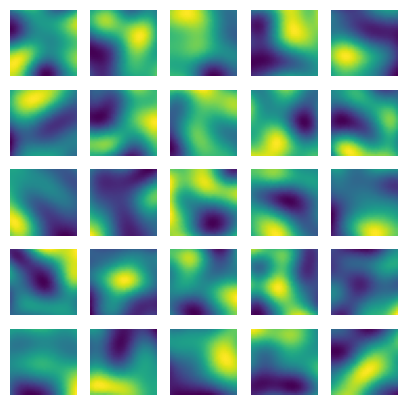

In [6]:
if rect:= False: # rectify or nay
    p = rectify(p_)
else:
    p = p_

ratemaps = plot_ratemaps(r[:-1,0], r[:-1,1], p, 5, figsize=(5,5), bins = 32)

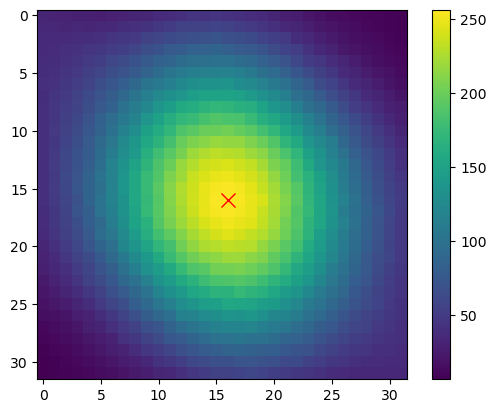

In [ ]:
# plot correlation between vector at [a,a] and all other pop. vecs.
a = 16
prod = np.sum(ratemaps[:,a, a, None,None]*ratemaps, axis = 0)
plt.imshow(prod.T)
plt.plot(a,a, "rx", markersize = 10)
plt.colorbar()